# 🏛️ UNIVERSIDAD NACIONAL DE SAN ANTONIO ABAD DEL CUSCO
### Facultad de Ingeniería Civil — Laboratorio de Materiales y Concreto
**Asignatura:** Tecnología del Concreto (IC152)  
**Docente:** ______________________________ | **Grupo / Brigada:** ______________________________  
**Semestre:** 2026-II  

---

# 🔬 PRÁCTICA N.° 9 (TC-09): Consistencia Normal y Tiempo de Fraguado del Cemento (Aguja de Vicat)
### Cuaderno Interactivo de Procesamiento y Control Normativo

> **Normativa Técnica Aplicable:**  
> **NTP 334.074:2019 (ASTM C187-23)** | **NTP 334.006:2024 (ASTM C191-21)** | **ASTM C305-20** | **NTP 334.009:2025 / 334.090:2025**

---

### 🎯 Objetivos de la Práctica
1. Determinar el porcentaje de agua de consistencia normal (penetración de sonda de 10 mm en 10 ± 1 mm, reportado a 0,5 %).
2. Interpolar el tiempo de fraguado inicial a exactamente 25,0 mm de penetración (redondeado al minuto).
3. Evaluar el fraguado inicial contra las especificaciones vigentes: 45 a 375 min (Portland I–V) o 45 a 420 min / 7 h (Adicionados IP/IS/IL).

## ⚙️ 1. Conexión con el Motor de Cálculo (`civillab_unsaac`)
Presiona **Ejecutar (▶)** en la siguiente celda antes de comenzar. Conecta las fórmulas normativas de la UNSAAC, tablas y graficadores.

In [1]:
# ==============================================================================
# CONEXIÓN CON LA LIBRERÍA DEL LABORATORIO (Ejecutar primero, no modificar)
# ==============================================================================
try:
    import civillab_unsaac as lab
except ModuleNotFoundError:
    # Si la librería aún no está instalada, la ubicamos automáticamente en el proyecto
    import sys
    from pathlib import Path
    raices = [
        Path.cwd(),
        *list(Path.cwd().parents)[:3],
        Path.cwd() / "08_SOFTWARE_LABORATORIO",
        Path.cwd() / "0003_UNSAAC_DOCENCIA" / "08_SOFTWARE_LABORATORIO",
    ]
    for r in raices:
        if (r / "civillab_unsaac").is_dir():
            sys.path.insert(0, str(r))
            break
    import civillab_unsaac as lab

from pathlib import Path
from civillab_unsaac import *
import matplotlib
try:
    get_ipython()
except NameError:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

try:
    from IPython.display import display
except ImportError:
    display = print

# Carpeta limpia para gráficos y fichas Excel de salida
_pkg_root = Path(lab.__file__).resolve().parents[1]
DIR_SALIDA = (_pkg_root / "fichas_generadas") if (_pkg_root / "notebooks").is_dir() else (Path.cwd() / "fichas_generadas")
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

print("✓ Suite CivilLab UNSAAC conectada y lista para calcular.")

✓ Suite CivilLab UNSAAC conectada y lista para calcular.


---
## 🧪 2. Consistencia Normal y Lecturas de Penetración Vicat
Ingresa las lecturas directamente como un diccionario `{tiempo_min: penetracion_mm}`. Las normas **NTP 334.009:2025 (Tabla 3, nota D)** y **NTP 334.090:2025 (Tabla 2, nota B)** aplican el límite mínimo (45 min) y máximo (375 o 420 min) **al tiempo de fraguado inicial**; el fraguado final se registra solo como dato informativo.


=== EVALUACIÓN NORMATIVA — TIEMPO DE FRAGUADO VICAT (ASTM C191 / NTP 334.006) ===
Cemento: Cemento Portland Puzolánico Tipo IP (Yura / Rumi) (Yura / Rumi) | Muestra: TC-B-CE-01
Especificación aplicable: NTP 334.090:2025 Tabla 2 nota B (Cementos Adicionados)
Masa cemento: 650.0 g | Agua consistencia normal: 27.5 % (178.8 mL) [Informar C187: 27.5 %]
Condiciones ambientales: Temp = 23.0 °C (Norma: 23 ± 2 °C) | HR = 65 %

RESULTADOS DEL ENSAYO:
• Fraguado Inicial (25 mm): 123 min (2.05 h) [interpolado: 123.0 min]
  -> Criterio único de aceptación (45 min <= t_i <= 420 min): CONFORME
• Fraguado Final (sin huella circular): 225 min (3.75 h)  [Sin límite normado; solo se informa]

DICTAMEN FINAL: APROBADO — CUMPLE ESPECIFICACIONES DE FRAGUADO


,Tanteo,Cemento (g),Agua (mL),Agua (%),Penetración Sonda (mm),¿Cumple 10 ± 1 mm?
0,1,650,169.0,26.0,5.0,No (muy seca)
1,2,650,185.3,28.5,15.0,No (muy fluida)
2,3,650,178.8,27.5,10.0,SÍ — Consistencia Normal


,Tiempo (min),Penetracion (mm)
0,30.0,40.0
1,60.0,39.5
2,90.0,36.0
3,105.0,32.0
4,120.0,26.5
5,135.0,19.0
6,150.0,12.0
7,180.0,4.0
8,210.0,1.0
9,225.0,0.5


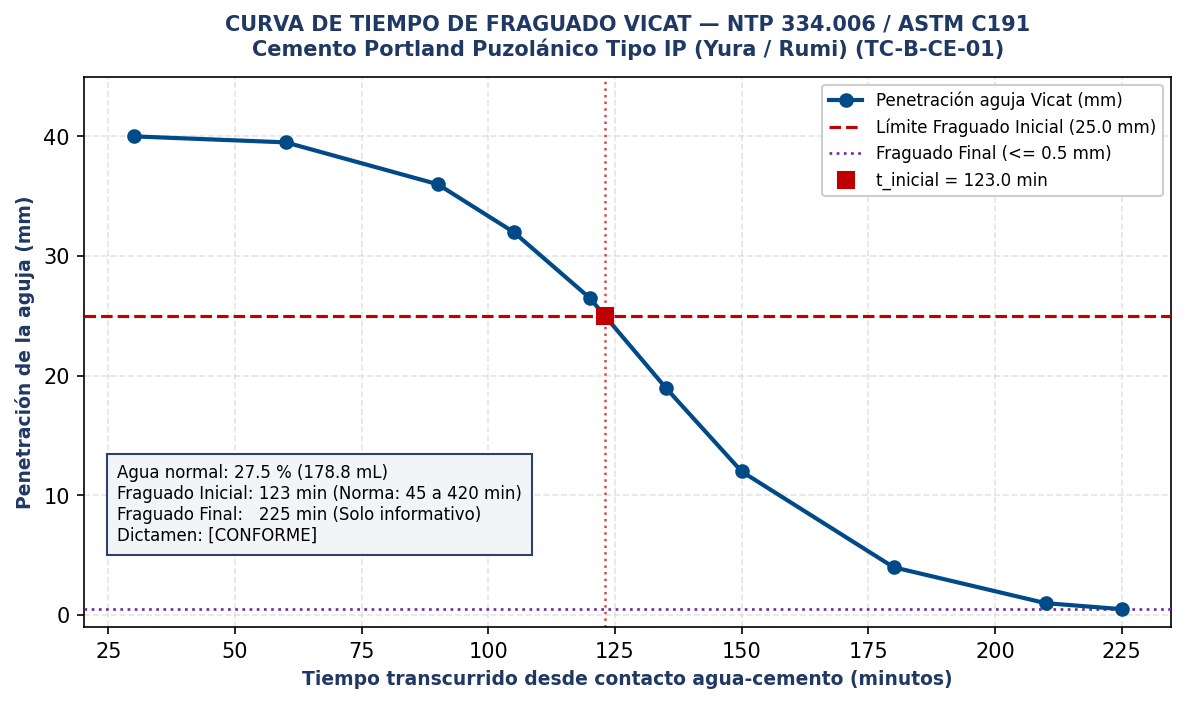

In [2]:
# 1. Tanteos previos de Consistencia Normal (ASTM C187: 650 g de cemento, sonda 10 mm)
tanteos_consistencia = pd.DataFrame([
    {"Tanteo": 1, "Cemento (g)": 650, "Agua (mL)": 169.0, "Agua (%)": 26.0, "Penetración Sonda (mm)": 5.0, "¿Cumple 10 ± 1 mm?": "No (muy seca)"},
    {"Tanteo": 2, "Cemento (g)": 650, "Agua (mL)": 185.3, "Agua (%)": 28.5, "Penetración Sonda (mm)": 15.0, "¿Cumple 10 ± 1 mm?": "No (muy fluida)"},
    {"Tanteo": 3, "Cemento (g)": 650, "Agua (mL)": 178.8, "Agua (%)": 27.5, "Penetración Sonda (mm)": 10.0, "¿Cumple 10 ± 1 mm?": "SÍ — Consistencia Normal"},
])
display(tanteos_consistencia)

# 2. Lecturas de penetración con aguja de 1 mm {tiempo_minutos: penetracion_mm}
lecturas_vicat = {
    30.0:  40.0,
    60.0:  39.5,
    90.0:  36.0,
    105.0: 32.0,
    120.0: 26.5,
    135.0: 19.0,
    150.0: 12.0,
    180.0: 4.0,
    210.0: 1.0,
    225.0: 0.5,  # No deja huella circular completa (verificado a los 90 s)
}

vicat = FraguadoVicatCemento(
    lecturas_vicat=lecturas_vicat,
    masa_cemento_g=650.0,
    agua_consistencia_porc=27.5,
    tipo_cemento="Cemento Portland Puzolánico Tipo IP (Yura / Rumi)",
    muestra_id="TC-B-CE-01",
    temp_ambiente_c=23.0,
    humedad_relativa_porc=65.0,
)

display(vicat.df)
print("\n" + vicat.diagnostico_tecnico())
graficar_fraguado_vicat(vicat, guardar_ruta=DIR_SALIDA / "TC-09_Curva_Fraguado_Vicat.png", mostrar=True)

---
## 📝 3. Conclusiones